<a href="https://colab.research.google.com/github/aakankshalahane/NLP-Projects-/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install nltk pandas matplotlib seaborn

In [2]:
# Import the libraries we need for our project

import nltk
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.sentiment import SentimentIntensityAnalyzer

# Download the sentiment dictionary
nltk.download('vader_lexicon')

print("All libraries are ready!")

All libraries are ready!


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


In [3]:
# A small collection of customer reviews

reviews = [
    "I absolutely love this product. It works perfectly!",
    "The customer service was amazing.",
    "This is the best purchase I have ever made.",
    "I am very happy with the quality.",
    "The delivery was quick and easy.",
    "I hate this product. It is completely useless.",
    "Very disappointed with the service.",
    "The quality is terrible and cheap.",
    "I will never buy this again.",
    "The product stopped working after one day.",
    "The package arrived today.",
    "The product has three different colours.",
    "I received my order yesterday.",
    "The product is okay, nothing special.",
    "It works as expected."
]

# Store the reviews in a DataFrame
df = pd.DataFrame(reviews, columns=["Review"])

# Display the dataset
df.head()

,Review
0,I absolutely love this product. It works perfe...
1,The customer service was amazing.
2,This is the best purchase I have ever made.
3,I am very happy with the quality.
4,The delivery was quick and easy.


In [4]:
# Load the VADER sentiment analyser

sentiment_analyser = SentimentIntensityAnalyzer()

print("Sentiment analyser is ready!")

Sentiment analyser is ready!


In [5]:
# Create a function to identify the sentiment

def find_sentiment(review):

    # Calculate the sentiment score
    score = sentiment_analyser.polarity_scores(review)

    # Use the compound score to decide the sentiment
    if score["compound"] >= 0.05:
        return "Positive"

    elif score["compound"] <= -0.05:
        return "Negative"

    else:
        return "Neutral"


# Apply the function to every review
df["Sentiment"] = df["Review"].apply(find_sentiment)

# Display the results
df

,Review,Sentiment
0,I absolutely love this product. It works perfe...,Positive
1,The customer service was amazing.,Positive
2,This is the best purchase I have ever made.,Positive
3,I am very happy with the quality.,Positive
4,The delivery was quick and easy.,Positive
5,I hate this product. It is completely useless.,Negative
6,Very disappointed with the service.,Negative
7,The quality is terrible and cheap.,Negative
8,I will never buy this again.,Neutral
9,The product stopped working after one day.,Negative


In [6]:
# Get the detailed sentiment scores for each review

scores = df["Review"].apply(
    lambda review: sentiment_analyser.polarity_scores(review)
)

# Add the scores to our dataset
df["Positive_Score"] = scores.apply(lambda x: x["pos"])
df["Negative_Score"] = scores.apply(lambda x: x["neg"])
df["Neutral_Score"] = scores.apply(lambda x: x["neu"])
df["Compound_Score"] = scores.apply(lambda x: x["compound"])

# Display the updated dataset
df.head()

,Review,Sentiment,Positive_Score,Negative_Score,Neutral_Score,Compound_Score
0,I absolutely love this product. It works perfe...,Positive,0.642,0.0,0.358,0.8746
1,The customer service was amazing.,Positive,0.487,0.0,0.513,0.5859
2,This is the best purchase I have ever made.,Positive,0.375,0.0,0.625,0.6369
3,I am very happy with the quality.,Positive,0.444,0.0,0.556,0.6115
4,The delivery was quick and easy.,Positive,0.367,0.0,0.633,0.4404


In [7]:
# Count the number of reviews in each category

sentiment_summary = df["Sentiment"].value_counts()

print(sentiment_summary)

Sentiment
Positive    5
Negative    5
Neutral     5
Name: count, dtype: int64


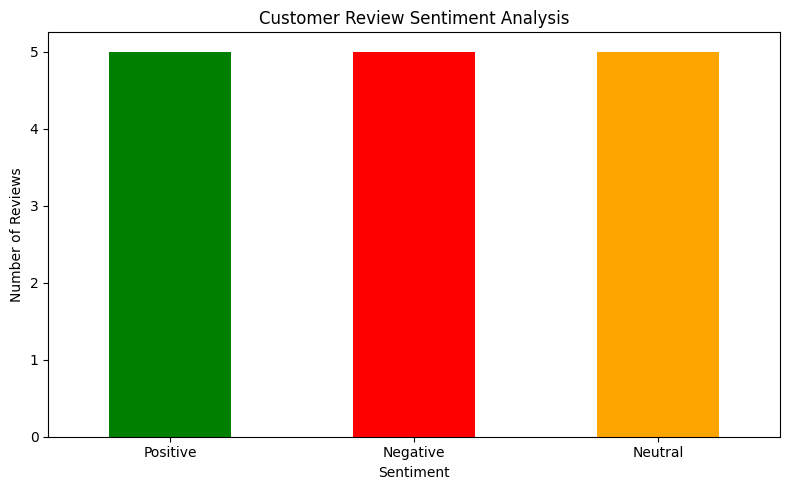

In [8]:
# Create a chart to understand the sentiment distribution

sentiment_summary.plot(
    kind="bar",
    figsize=(8, 5),
    color=["green", "red", "orange"]
)

plt.title("Customer Review Sentiment Analysis")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [9]:
# Add columns for manual annotation and quality checking

df["Human_Review"] = "Pending"
df["Corrected_Sentiment"] = df["Sentiment"]

# Display the annotation columns
df[["Review", "Sentiment", "Human_Review", "Corrected_Sentiment"]]

,Review,Sentiment,Human_Review,Corrected_Sentiment
0,I absolutely love this product. It works perfe...,Positive,Pending,Positive
1,The customer service was amazing.,Positive,Pending,Positive
2,This is the best purchase I have ever made.,Positive,Pending,Positive
3,I am very happy with the quality.,Positive,Pending,Positive
4,The delivery was quick and easy.,Positive,Pending,Positive
5,I hate this product. It is completely useless.,Negative,Pending,Negative
6,Very disappointed with the service.,Negative,Pending,Negative
7,The quality is terrible and cheap.,Negative,Pending,Negative
8,I will never buy this again.,Neutral,Pending,Neutral
9,The product stopped working after one day.,Negative,Pending,Negative


In [10]:
# Example: mark the first review as manually checked

df.loc[0, "Human_Review"] = "Reviewed"

# Keep the corrected label only after human verification
df.loc[0, "Corrected_Sentiment"] = "Positive"

df.head()


,Review,Sentiment,Positive_Score,Negative_Score,Neutral_Score,Compound_Score,Human_Review,Corrected_Sentiment
0,I absolutely love this product. It works perfe...,Positive,0.642,0.0,0.358,0.8746,Reviewed,Positive
1,The customer service was amazing.,Positive,0.487,0.0,0.513,0.5859,Pending,Positive
2,This is the best purchase I have ever made.,Positive,0.375,0.0,0.625,0.6369,Pending,Positive
3,I am very happy with the quality.,Positive,0.444,0.0,0.556,0.6115,Pending,Positive
4,The delivery was quick and easy.,Positive,0.367,0.0,0.633,0.4404,Pending,Positive


In [11]:
# Save the final dataset as a CSV file

df.to_csv("Sentiment_Analysis_Dataset.csv", index=False)

print("Your sentiment analysis dataset has been saved!")

Your sentiment analysis dataset has been saved!


In [12]:
# Download the CSV file to your computer

from google.colab import files

files.download("Sentiment_Analysis_Dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
print("SENTIMENT ANALYSIS PROJECT SUMMARY")
print("-----------------------------------")

print("Total Reviews:", len(df))
print("Positive Reviews:", (df["Sentiment"] == "Positive").sum())
print("Negative Reviews:", (df["Sentiment"] == "Negative").sum())
print("Neutral Reviews:", (df["Sentiment"] == "Neutral").sum())

print("\nProject completed successfully!")

SENTIMENT ANALYSIS PROJECT SUMMARY
-----------------------------------
Total Reviews: 15
Positive Reviews: 5
Negative Reviews: 5
Neutral Reviews: 5

Project completed successfully!
